<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s Girl with a pearl earring: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [23]:
import sys
sys.path.append('..')  # adjust if library lives elsewhere

import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from copy import deepcopy
from itertools import product
from typing import Callable
from tqdm import tqdm

from PIL import Image, ImageDraw
from scipy.stats import wilcoxon

<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

In [27]:
# configuration
IMAGE_PATH   = 'girl_pearl_earing.png'  
IMG_WIDTH    = 300
IMG_HEIGHT   = 400
N_TRIANGLES  = 100

Image loaded: (300, 400) — array shape (400, 300, 3)


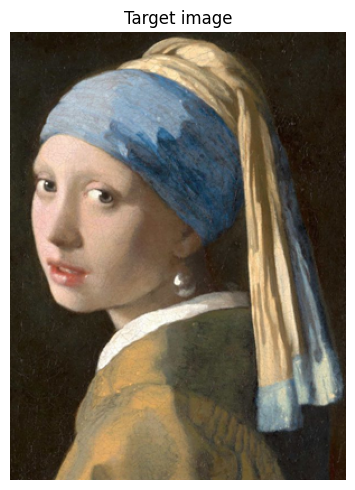

In [ ]:
# load image
target_image = Image.open(IMAGE_PATH).convert('RGB').resize((IMG_WIDTH, IMG_HEIGHT)) # test retrieve with RGBA
TARGET_ARRAY = np.array(target_image, dtype=np.float32)  # shape (400, 300, 3)

print(f'Image loaded: {target_image.size} — array shape {TARGET_ARRAY.shape}')

plt.figure(figsize=(4, 5))
plt.imshow(target_image)
plt.title('Target image')
plt.axis('off')
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Encoding

Each solution is a list of **100 triangles**. Each triangle is encoded as a flat list of **9 floats**:

```
[ x1, y1, x2, y2, x3, y3,  R, G, B ]
- vertices (normalised 0–1)
- colour (0–255)
```


### Fitness
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 3} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$